### Model Validation Report (include model name, project/group name and the date)

| Field | Entry |
|---|---|
| Model name | Bank Account Fraud Detection Model |
| Model developer (1LOD) | Joshua Sanchez |
| Model validator (2LOD) | Anna Pope |
| Model version / GitHub commit reviewed | Version 1 |
| Model tier (1 / 2 / 3) | |
| Date of validation | 10/29/26 |
| Overall conclusion | Approved / Approved with conditions / Not approved |

#### *Executive Summary*

The model is meant to find the probability that a bank account opening is fraudulent. If the probability is high enough (based on thresholds) then it flags the application as fraudulent.

| Severity | Number of findings |
|---|---|
| High | Model has high recall, but low precision/false alarms. During validation, the area under the ROC curve was .88 (model can determine the difference between a fraud/nonfraud 88% of the time). |
| Medium | During data cleaning, outliers were kept into the training data. |
| Low | The actual documentation of the data on the GitHub (where the data was pulled from) has some issues with the ranges of the values. |

#### *i. Scope of Review*

Scope of this review covers;

* Fraud Detection Model Documentation (.ipynb)
* Bank Account Fraud Detection Model (.ipynb)

Within the bank account fraud detection model there is various code and data that I ran for this model. Nothing went untested.

#### *ii. Purpose, Business Context and Intended Use*

**Purpose:** Purpose of this model is to determine if an account being opened is fraudulent activity
<br>

**Business Context:** Fraud detection models are systematic approaches to identify, and therefore prevent, fraudulent activity. This model sits at the front of the account opening process. It scores each application so the bank can approve it, decline it, or refer it for review. The institution this model is built for is assumed to be a large US bank with more than $30 billion in total assets.
<br>

**Intended Use:** Score individual account opening applications using only information available at the time of application and estimate the probability of fraud.

#### *iii. Data Review*

Data for this model comes from Kaggle dataset (https://www.kaggle.com/datasets/sgpjesus/bank-account-fraud-dataset-neurips-2022?select=Base.csv). From the documentation on the website this data "...represents a synthetic, feature-engineered bank account opening application in tabular format. These were generated using a CTGAN trained on a real-world anonymized dataset for bank account opening fraud." and there is no specific date for this data, other than the dataset itself was uploaded in 2022. One issue I see with the documentation of this data is that the range of data for specific columns is incorrect.

Doing some exploratory data analysis, the binary target variable is called "fraud_bool" and holds for the assumption under logistic regression. There are no missing values/NA values in the columns (instead they are coded in as -1), but there are a lot of outliers within some of the numeric columns. In order to preserve the logistic regression assumptions, these outliers will have to be taken care of during the data cleaning step. 

**Leakage check:** (is every feature available at the time the decision is made? Was any preprocessing — scaling, filling missing values, capping — fitted on training data only?) Scaling and capping columns was not done. Since there are no missing values, that also did not to be completed. Every feature is available at the time the decision has been made.

In [39]:
# Data checks: row count, target rate, missing values, duplicates, value ranges

import kagglehub
import pandas as pd

path = kagglehub.dataset_download("sgpjesus/bank-account-fraud-dataset-neurips-2022",path="Base.csv")
data = pd.read_csv(path)

# from documentation 'fraud_bool' is the target variable
print(data["fraud_bool"]) # taking a look at the target variable, which is binary

# missing values/na values in each column
print(data.isna().sum()) # no missing values in any of the columns, but missing values are coded in as -1

# doing some investigating of the data; general summary statistics as well as the shape of the data
pd.set_option("display.max_columns", None)
data.describe() # noting some negative values in some of the columns where a negative value wouldn't make sense
                # intended_balcon_ammount -> in documentation says it ranges from [0,108] but a value of ~113 occurs
                # zip_count_4w -> in documentation says it ranges from [0, 5767] but a value of 6700 occurs
                # outliers seen in prev_address_month, days_since_request, zip_count_4w, proposed_credit_limit, session_length_in_minutes
                # biggest takeaway here: some inconsistencies w/ the documentation ranges, outliers do exist numerical columns

# data cleaning would involve working with outliers for this dataset



0         0
1         0
2         0
3         0
4         0
         ..
999995    0
999996    0
999997    0
999998    0
999999    0
Name: fraud_bool, Length: 1000000, dtype: int64
fraud_bool                          0
income                              0
name_email_similarity               0
prev_address_months_count           0
current_address_months_count        0
customer_age                        0
days_since_request                  0
intended_balcon_amount              0
payment_type                        0
zip_count_4w                        0
velocity_6h                         0
velocity_24h                        0
velocity_4w                         0
bank_branch_count_8w                0
date_of_birth_distinct_emails_4w    0
employment_status                   0
credit_risk_score                   0
email_is_free                       0
housing_status                      0
phone_home_valid                    0
phone_mobile_valid                  0
bank_months_count     

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,credit_risk_score,email_is_free,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,session_length_in_minutes,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.0,1000000.000000
mean,0.011029,0.562696,0.493694,16.718568,86.587867,33.689080,1.025705e+00,8.661499,1572.692049,5665.296605,4769.781965,4856.324016,184.361849,9.503544,130.989595,0.529886,0.417077,0.889676,10.839303,0.222988,515.851010,0.025242,7.544940,0.576947,1.018312,0.0,3.288674
std,0.104438,0.290343,0.289125,44.046230,88.406599,12.025799,5.381835e+00,20.236155,1005.374565,3009.380665,1479.212612,919.843934,459.625329,5.033792,69.681812,0.499106,0.493076,0.313293,12.116875,0.416251,487.559902,0.156859,8.033106,0.494044,0.180761,0.0,2.209994
min,0.000000,0.100000,0.000001,-1.000000,-1.000000,10.000000,4.036860e-09,-15.530555,1.000000,-170.603072,1300.307314,2825.748405,0.000000,0.000000,-170.000000,0.000000,0.000000,0.000000,-1.000000,0.000000,190.000000,0.000000,-1.000000,0.000000,-1.000000,0.0,0.000000
25%,0.000000,0.300000,0.225216,-1.000000,19.000000,20.000000,7.193246e-03,-1.181488,894.000000,3436.365848,3593.179135,4268.368423,1.000000,6.000000,83.000000,0.000000,0.000000,1.000000,-1.000000,0.000000,200.000000,0.000000,3.103053,0.000000,1.000000,0.0,1.000000
50%,0.000000,0.600000,0.492153,-1.000000,52.000000,30.000000,1.517574e-02,-0.830507,1263.000000,5319.769349,4749.921161,4913.436941,9.000000,9.000000,122.000000,1.000000,0.000000,1.000000,5.000000,0.000000,200.000000,0.000000,5.114321,1.000000,1.000000,0.0,3.000000
75%,0.000000,0.800000,0.755567,12.000000,130.000000,40.000000,2.633069e-02,4.984176,1944.000000,7680.717827,5752.574191,5488.083356,25.000000,13.000000,178.000000,1.000000,1.000000,1.000000,25.000000,0.000000,500.000000,0.000000,8.866131,1.000000,1.000000,0.0,5.000000
max,1.000000,0.900000,0.999999,383.000000,428.000000,90.000000,7.845690e+01,112.956928,6700.000000,16715.565404,9506.896596,6994.764201,2385.000000,39.000000,389.000000,1.000000,1.000000,1.000000,32.000000,1.000000,2100.000000,1.000000,85.899143,1.000000,2.000000,0.0,7.000000


#### *iv. Conceptual Soundness*


| Assumption | How tested | Result | Holds? |
|---|---|---|---|
| Outcome is binary | The dataset being used had a column called "fraud_bool", which is 1 (fraud) or 0 (not fraud) | This binary outcome variable is being used as the target variable | This holds for the assumption |
| Independence of observations | In documentation from data, it was noted that all observations are independent of each other | Documentation provides sufficient information that the data is independent | This holds for the assumption |
| No extreme/influencial outliers | Outliers were detected with a 1.5 times IQR rule. However, outliers were not removed due to their outcomes being important | Outliers were detected, but not removed | Since influencial outliers were detected by not removed, this does not hold for the assumption |
| No severe multicollinearity | There were 3 velocity columns that were highly correlated, only choose one of these columns for the model since it had no NaN values | Selecting one of the columns to remove solves the multicollinearity in the dataset | This holds for the assumption |
| Linearity of log odds | Tested by using the Box-Tidwell tests | Some columns were flagged for having departure from linearity, but they were not removed | This does not hold for the assumptions| 

#### *v. Replication*

Copying and pasting the copy from Joshua's fraud model. Some sections within this code have been commented out to reduce the amount of things being printed (such as the correlation matrix). Limited comments within his code have made it difficult to understand what some of the code/loops are doing.

*Table of coefficients and interger is at the bottom.*

In [33]:
# Replication: rerun the developer's code and recompute their reported numbers
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import kagglehub
import sys
import statsmodels.api as sm 

#Read in Functions
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report
from sklearn.metrics import accuracy_score, confusion_matrix,precision_score, recall_score,f1_score,roc_curve, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# print(pd.__version__)
# print(np.__version__)
# print(sklearn.__version__)
# print(sys.version)

# Reading in Data
path = kagglehub.dataset_download("sgpjesus/bank-account-fraud-dataset-neurips-2022",path="Base.csv")
data = pd.read_csv(path)

#Create Data frame only using numeric and boolean columns
columns = [c for c in data.columns if c not in ['fraud_bool',
                                               'payment_type',
                                               'employment_status',
                                               'housing_status',
                                                'source',
                                               'device_os',
                                               'device_fraud_count']]

X = data[columns].astype(float)   # turns True/False columns into 1.0 / 0.0

#Correlation Matrix
# corrmat = X.select_dtypes(include=['number']).corr()
# fig = plt.figure(figsize = (20,20))

# sns.heatmap(corrmat, vmax = 0.8, square = True)
# plt.show()

# uncommented section; not sure what is going on here
numeric_cols = [c for c in data.columns if c not in [
    'fraud_bool', 'device_fraud_count', 'payment_type', 'employment_status', 'housing_status', 'source', 'device_os', 'velocity_6h', 'velocity_4w'
]]
cont = [c for c in numeric_cols if data[c].nunique() > 2]
num = data[cont]

q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

is_out = (num < low) | (num > high)

summary = pd.DataFrame({
    'n_outliers': is_out.sum(),
    'pct_outliers': (is_out.mean() * 100).round(2),
    'min': num.min(),
    'p99': num.quantile(0.99),
    'max': num.max(),
}).sort_values('pct_outliers', ascending=False)
# print(summary)

# Visual check, one box plot per column
# num.plot(kind='box', subplots=True, layout=(5, 5), figsize=(18, 14))

sentinel_cols = ['prev_address_months_count', 'current_address_months_count',
                 'bank_months_count', 'session_length_in_minutes',
                 'device_distinct_emails_8w', 'intended_balcon_amount']

counts = (data[sentinel_cols] < 0).sum()
pct = ((data[sentinel_cols] < 0).mean() * 100).round(2)
# print(pd.DataFrame({'n_negative': counts, 'pct_negative': pct}))

# Does being missing carry fraud signal?
for c in sentinel_cols:
    miss = data[c] < 0
    # print(c, "fraud rate if missing:", round(data.loc[miss, 'fraud_bool'].mean(), 4),
    #       "| if present:", round(data.loc[~miss, 'fraud_bool'].mean(), 4))
    
# ---------- 1. Missing value codes ----------
sentinel_cols = ['prev_address_months_count', 'current_address_months_count',
                 'bank_months_count', 'session_length_in_minutes',
                 'device_distinct_emails_8w', 'intended_balcon_amount']
indicator_cols = ['prev_address_months_count', 'intended_balcon_amount',
                  'bank_months_count']

df = data.copy()

# Indicators first: 1 if the value was a negative code (or is already NaN)
for c in indicator_cols:
    df[c + '_missing'] = ((df[c] < 0) | df[c].isna()).astype(int)

# Convert the codes to NaN. Cast to float first so NaN can be stored.
for c in sentinel_cols:
    df[c] = df[c].astype('float64')
    df.loc[df[c] < 0, c] = np.nan

# ---------- 2. Column lists ----------
cat_cols = ['payment_type', 'employment_status', 'housing_status',
            'source', 'device_os']
drop_cols = ['fraud_bool', 'device_fraud_count', 'month', 'velocity_6h', 'velocity_4w']
numeric_cols = [c for c in df.columns if c not in cat_cols + drop_cols]

# Turn True/False columns into 1/0
bool_cols = df[numeric_cols].select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)

X = df[numeric_cols + cat_cols]
y = df['fraud_bool']

# ---------- 3. Checks (run these before modeling) ----------
# print("Non numeric columns (should be empty):",
#       X[numeric_cols].select_dtypes(exclude='number').columns.tolist())
# print("NaN counts (should be nonzero only for the six converted columns):")
# print(X[numeric_cols].isna().sum()[lambda s: s > 0])
# print("Indicator means:")
# print(X[[c + '_missing' for c in indicator_cols]].mean().round(4))

# ---------- 4. Split ----------
X_temp, X_test, y_temp, y_test = train_test_split( X, y, test_size=0.15, stratify=y, random_state=27695)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15/0.85, stratify=y_temp, random_state=27695)

# ---------- 5. Preprocessing and model in one pipeline ----------
num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])
model = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=10000)),
])

model.fit(X_train, y_train)

# ---------- 6. Validation results ----------
y_val_pred = model.predict(X_val)
y_val_proba = model.predict_proba(X_val)[:, 1]
# print("Accuracy:", accuracy_score(y_val, y_val_pred))
# print(classification_report(y_val, y_val_pred))
# print("ROC AUC:", roc_auc_score(y_val, y_val_proba))
# print("PR AUC:", average_precision_score(y_val, y_val_proba))
# print("Fraud rate in validation set:", y_val.mean())

validation_binary = model.predict(X_val)
validation_probability = model.predict_proba(X_val) # class zero and one probabilities

# creating a table of all the coefficients and the intercept for the model (trained on X_train, Y_train)
coe = model.named_steps['clf'].coef_[0]
inter = model.named_steps['clf'].intercept_[0]

feature_names = model.named_steps['prep'].get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coe
})

print(coefficients)
print("Intercept:", inter)

                                   Feature  Coefficient
0                              num__income     0.279274
1               num__name_email_similarity    -0.351188
2           num__prev_address_months_count     0.091982
3        num__current_address_months_count    -0.033089
4                        num__customer_age     0.217526
5                  num__days_since_request     0.068290
6              num__intended_balcon_amount     0.015196
7                        num__zip_count_4w     0.092228
8                        num__velocity_24h     0.041116
9                num__bank_branch_count_8w    -0.055543
10   num__date_of_birth_distinct_emails_4w    -0.111374
11                  num__credit_risk_score     0.147393
12                      num__email_is_free     0.308690
13                   num__phone_home_valid    -0.486980
14                 num__phone_mobile_valid    -0.107258
15                  num__bank_months_count     0.160478
16                    num__has_other_cards    -0

#### *vi. Independent Testing*

(your own out-of-sample tests, using metrics suited to the model type, e.g.)
- *PD:* AUC / Gini, KS, calibration (predicted vs actual default rate by decile)
- *Fraud:* PR-AUC (state the random baseline = fraud rate), ROC-AUC, recall and precision at the chosen threshold, false alarms per fraud caught
- *VaR:* exception count, Basel traffic light, Kupiec and Christoffersen tests, backtest window including a stress period

(also include stability (cross-validation or rolling windows) and sensitivity to key choices such as the threshold or lookback window)

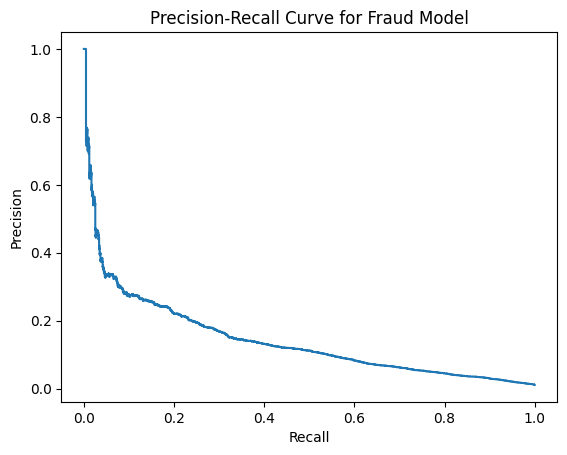

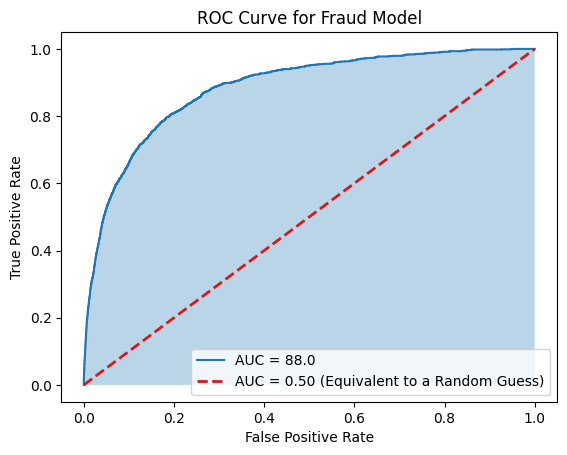

The number of false alarms/false positives is 51052
The precision for the fraud model is 0.0285
The recall for the fraud model is 0.9063


In [34]:
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve, recall_score, precision_score, average_precision_score
val_prob = validation_probability[:,1] # class one (fraud) probability

# precision curve analysis
precision, recall, thresholds = precision_recall_curve(y_val, val_prob)
pr_auc = average_precision_score(y_val, val_prob)

plt.plot(recall, precision)
plt.title("Precision-Recall Curve for Fraud Model")
plt.ylabel("Precision")
plt.xlabel("Recall")
plt.show()

# roc auc curve and analysis
fpr, tpr, thresholds = roc_curve(y_val, val_prob)
auc = roc_auc_score(y_val, val_prob)

plt.plot(fpr,tpr, label=f"AUC = {round(auc,2)*100}")
plt.fill_between(fpr, tpr, alpha=0.3)
plt.plot([0,1],[0,1], label="AUC = 0.50 (Equivalent to a Random Guess)", color="#d7191c", linestyle="--", linewidth=2)
plt.legend(loc=4)
plt.title("ROC Curve for Fraud Model")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

# false alarms, precision and recall | threshold determines is .31
threshold_prec_acc = (val_prob >= 0.31).astype(int)
precision = precision_score(y_val, threshold_prec_acc)
recall = recall_score(y_val, threshold_prec_acc)
fp=len(np.where((y_val==0) & (threshold_prec_acc==1))[0])

print(f"The number of false alarms/false positives is {fp}")
print(f"The precision for the fraud model is {round(precision,4)}")
print(f"The recall for the fraud model is {round(recall,4)}")

#### *vii. Benchmark / Challenger Model*

Below is the alternative model, constructed as a Random Forest. Using the same pipeline and preprocessor steps, I just altered the actual model being deployed. 

| Metric | Developer model | Challenger model |
|---|---|---|
| False alarms/false positives | 51052 | 49382 |
| Precision | 0.0285 | 0.029 |
| Recall | 0.9063 | 0.8912 |

No significant differences between the two models but, the Random Forest model has slightly less false alarms and a higher precision rate despite the lower recall.

In [37]:
# Challenger model: random forest for classification 

from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# ---------- 1. Missing value codes ----------
sentinel_cols = ['prev_address_months_count', 'current_address_months_count',
                 'bank_months_count', 'session_length_in_minutes',
                 'device_distinct_emails_8w', 'intended_balcon_amount']
indicator_cols = ['prev_address_months_count', 'intended_balcon_amount',
                  'bank_months_count']

df = data.copy()

# Indicators first: 1 if the value was a negative code (or is already NaN)
for c in indicator_cols:
    df[c + '_missing'] = ((df[c] < 0) | df[c].isna()).astype(int)

# Convert the codes to NaN. Cast to float first so NaN can be stored.
for c in sentinel_cols:
    df[c] = df[c].astype('float64')
    df.loc[df[c] < 0, c] = np.nan

# keeping the data cleaning steps from above

# ---------- 2. Column lists ----------
cat_cols = ['payment_type', 'employment_status', 'housing_status',
            'source', 'device_os']
drop_cols = ['fraud_bool', 'device_fraud_count', 'month', 'velocity_6h', 'velocity_4w']
numeric_cols = [c for c in df.columns if c not in cat_cols + drop_cols]

# Turn True/False columns into 1/0
bool_cols = df[numeric_cols].select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)

X = df[numeric_cols + cat_cols]
y = df['fraud_bool']

# keeping these data cleaning steps as well

# ---------- 3. Split ----------
X_temp, X_test, y_temp, y_test = train_test_split( X, y, test_size=0.15, stratify=y, random_state=27695)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15/0.85, stratify=y_temp, random_state=27695)

# ---------- 5. Preprocessing and model in one pipeline ----------
num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])
challenger_model = Pipeline([
    ('prep', clone(preprocessor)),
    ('clf', RandomForestClassifier(
        n_estimators=300, # starting with just 100 trees (higher -> more stable)
        class_weight='balanced', # allows emphasis on the fraud class (since there's so little)
        max_depth=10, # how many decisions can a decision tree make
        min_samples_leaf=5, # how many leafs there must be at the end of a node (higher -> more stable)
        max_features='sqrt', # way to determine how many features a tree covers
        random_state=27695,
        n_jobs=-1
    ))
])
challenger_model.fit(X_train,y_train)

validation_binary = challenger_model.predict(X_val)
validation_probability = challenger_model.predict_proba(X_val)

# creating a table of all the coefficients and the intercept for the model (trained on X_train, Y_train)
# coe = challenger_model.named_steps['clf'].coef_[0]
# inter = challenger_model.named_steps['clf'].intercept_[0]

# feature_names = challenger_model.named_steps['prep'].get_feature_names_out()

# coefficients = pd.DataFrame({
#     "Feature": feature_names,
#     "Coefficient": coe
# })

# print(coefficients)
# print("Intercept:", inter)

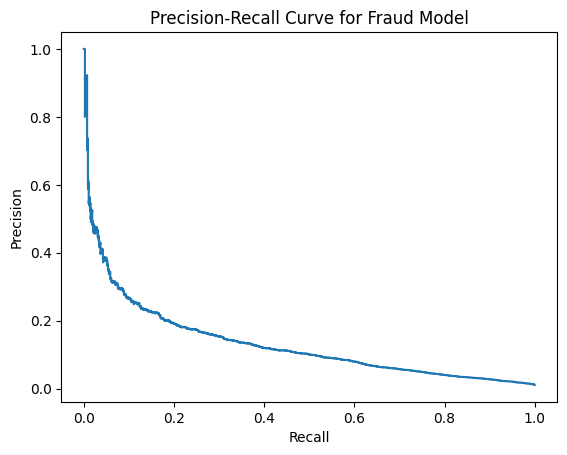

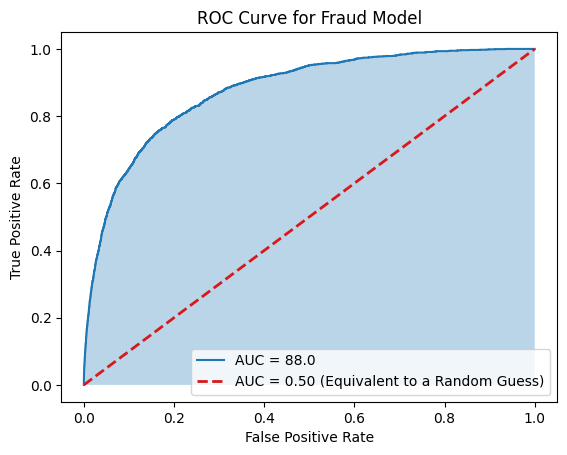

The number of false alarms/false positives is 49382
The precision for the fraud model is 0.029
The recall for the fraud model is 0.8912


In [38]:
# validating
val_prob = validation_probability[:,1] # class one (fraud) probability

# precision curve analysis
precision, recall, thresholds = precision_recall_curve(y_val, val_prob)
pr_auc = average_precision_score(y_val, val_prob)

plt.plot(recall, precision)
plt.title("Precision-Recall Curve for Fraud Model")
plt.ylabel("Precision")
plt.xlabel("Recall")
plt.show()

# roc auc curve and analysis
fpr, tpr, thresholds = roc_curve(y_val, val_prob)
auc = roc_auc_score(y_val, val_prob)

plt.plot(fpr,tpr, label=f"AUC = {round(auc,2)*100}")
plt.fill_between(fpr, tpr, alpha=0.3)
plt.plot([0,1],[0,1], label="AUC = 0.50 (Equivalent to a Random Guess)", color="#d7191c", linestyle="--", linewidth=2)
plt.legend(loc=4)
plt.title("ROC Curve for Fraud Model")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

# false alarms, precision and recall | threshold determines is .31
threshold_prec_acc = (val_prob >= 0.31).astype(int)
precision = precision_score(y_val, threshold_prec_acc)
recall = recall_score(y_val, threshold_prec_acc)
fp=len(np.where((y_val==0) & (threshold_prec_acc==1))[0])

print(f"The number of false alarms/false positives is {fp}")
print(f"The precision for the fraud model is {round(precision,4)}")
print(f"The recall for the fraud model is {round(recall,4)}")

#### *viii. Limitations Review*
*Mirrors developer section vi (limitations)*

The developers limitations for the model are as follows;

* Logistic regression does not capture interactions or nonlinear effects unless they are engineered into the features
* Class weighting inflates predicted probabilities relative to the true fraud rate, so scores are rankings more than calibrated probabilities. If calibrated probabilities are needed, add a calibration step and check a calibration curve. 
* The default 0.5 threshold flags many false alarms for a rare event, with increasing false positive rate as the threshold is decreased (see Section III). 
* Missing value codes: Missing values coded as negative numbers (negative one in five columns, and negative values in intended_balcon_amount) were converted to NaN, imputed with the training set median, and paired with missing indicator columns for prev_address_months_count, intended_balcon_amount, and bank_months_count. This keeps a code such as negative one from being treated as a real value, which would distort the coefficients. The limitation is that median imputation understates variance, and the model depends on how the bank records missing data. A change in recording practice would change the indicator columns and the scores. 
* Linearity: Box-Tidwell tests found significant departures from linearity in 9 of 15 continuous features, and the model does not correct for them. No capping or transformation was applied, which keeps each coefficient interpretable as a single odds ratio. Splines or binning could improve fit but would reduce that interpretability. 
* The data is synthetic, so real-world performance may differ.

Developer covers majority of limitations found from the data and the model. Limitations I propose;

* Inconsistencies with the ranges found from the data source, but that doesn't hugely impact the model. 
* Standardizing the data rather than normalizing the data (and the reasons for standardizing the data)
* Model can, of course, only be used on bank account opening requests

#### *ix. Ongoing Monitoring Review*

Developer does not touch upon ongoing monitoring. Suggestions I would make for this section;

* Ensuring that missing data remains as -1 (that way the pipeline/data cleaning steps set up in the model still work) and making sure that the data being used in this model has integrity
* Analyzing the quality of predictions (such as precision, recall etc.) to make sure that the model still works as it had when first created
* Keeping up with what a fraudulent transaction in the data looks like, that way the model can be changed based on that

#### *x. Findings*

| Rating | Meaning | Example |
|---|---|---|
| High | Results cannot be trusted or reproduced | Code does not run; data leakage |
| Medium | Usable, but a real weakness | Untested assumption; documentation does not match code |
| Low | Documentation or presentation issue | Wrong date; unclear wording |

| ID | Section | Finding | Evidence (cell, number or test) | Rating | Required action |
|---|---|---|---|---|---|
| F1 | Model Performance and Independent Testing | Model results have an extremely low precision which leads to a lot of false positives. | Evidence in Independent Testing section | Medium | Evaluate other features or a different threshold to attempt to improve the precision while maintaining a good recall |
| F2 | Data preparation | Despite investigating outliers, they were not handled | Evidence in Conceptual Soundness | Medium | Use plots and/or other metrics to determine outliers, then create a threshold for features with outliers to remove them (or take another action, this is just a suggestion)|

#### *xi. Overall Conclusion*

Approved with conditions. 

Although this model has an issue with low precision, meaning a lot of false alarms, it does have a high recall rate meaning that the model actually finds a high percentage of fraud accounts. However, because of the low precision, this model needs a little bit more tuning with either the features selected, or the thresholds selected or changing something that relates back to the conceptual soundness of utilizing logistic regression. 

#### *xii. Developer Response*
*Completed by the model developer*

| ID | Agree / Dispute | Response or action taken | Date |
|---|---|---|---|
| F1 | | | |
| F2 | | | |

**Validator sign-off:** (for each finding, state whether it is closed, accepted with conditions, or still open)